In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange
from scipy.special import jv

### radial grid

In [3]:
dx = 0.001     
x = np.arange(0.0, 1.9, dx)

# Vector Potential

https://linkinghub.elsevier.com/retrieve/pii/S0375960118309587


$$
A_z(r) = m\omega_C F_0 J_2(\lambda r)\\
A_{\theta} = B_z
$$

in the unit of the code $m=1,\; e=1$. Thus $\omega_C = B_z$

In [4]:
Bz = 4

def A_z(r,Bz):
    F_0 = 1
    lambd =7.5
    result = Bz*F_0*jv(2, lambd*r)
    return result

# Magnetic field

$$
B_{\theta} = - \partial_r A_z\\
B_z = \frac{m\omega}{e}
$$

In [5]:
def B_th(r, Bz):
    F_0 = 1
    lambd =7.5
    return - Bz*F_0*0.5*(jv(1, lambd*r)-jv(3, lambd*r))*lambd

C:\Users\Utente\AppData\Local\Temp\ipykernel_29032\2146882726.py:20: RuntimeWarning: invalid value encountered in divide
  q = PhiTh/PhiT


Text(0.5, 0.98, 'Magnetic configuration')

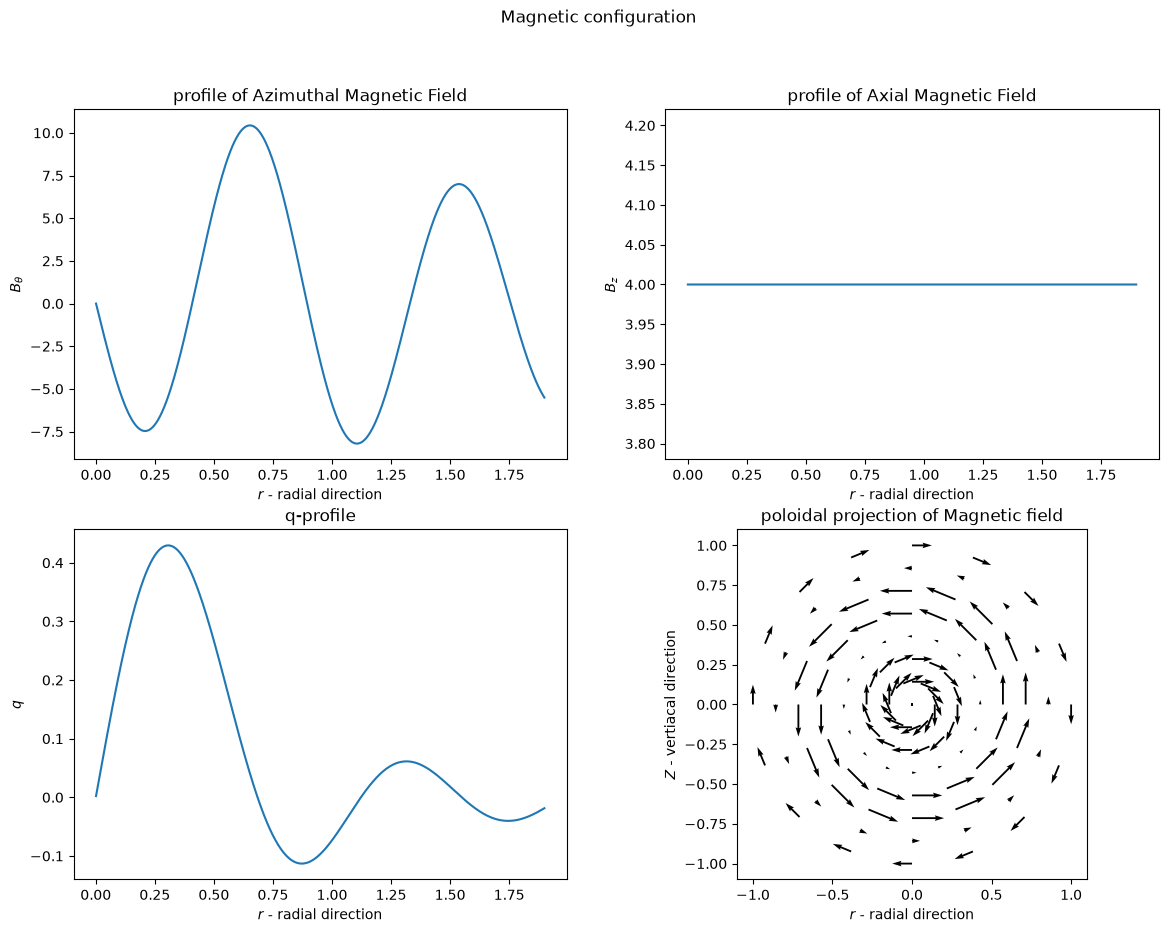

In [7]:
fig, ax = plt.subplots(2,2, figsize=(14,10))

ax[0,0].plot(x, B_th(x, Bz))
ax[0,0].set_xlabel('$r$ - radial direction')
ax[0,0].set_ylabel('$B_{\\theta}$')
ax[0,0].set_title('profile of Azimuthal Magnetic Field')


B_z = np.zeros(x.shape)
B_z = B_z + Bz
ax[0,1].plot(x, B_z)
ax[0,1].set_xlabel('$r$ - radial direction')
ax[0,1].set_ylabel('$B_z$')
ax[0,1].set_title('profile of Axial Magnetic Field')

# Toroidal flux
PhiT = Bz * np.pi*x**2
PhiTh = x * A_z(x, Bz)

q = PhiTh/PhiT
ax[1,0].plot(x, q)
ax[1,0].set_xlabel('$r$ - radial direction')
ax[1,0].set_ylabel('$q$')
ax[1,0].set_title('q-profile')

theta = np.linspace(0, 2*np.pi, 17)[:-1]
r = np.linspace(0,1,8)

R, TH = np.meshgrid(r,theta)

X = R*np.cos(TH)
Y = R*np.sin(TH)

Bth = B_th(R, Bz)
U = -np.sin(TH)*Bth
V =  np.cos(TH)*Bth

ax[1,1].quiver(X,Y,U,V)
ax[1,1].set_xlabel('$r$ - radial direction')
ax[1,1].set_ylabel('$Z$ - vertiacal direction')
ax[1,1].set_aspect('equal')
ax[1,1].set_title('poloidal projection of Magnetic field')
fig.suptitle('Magnetic configuration')

# The magnetic field lines ... to be continued ...

c:\Users\Utente\Projects\Marseille\.venv\Lib\site-packages\matplotlib\patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


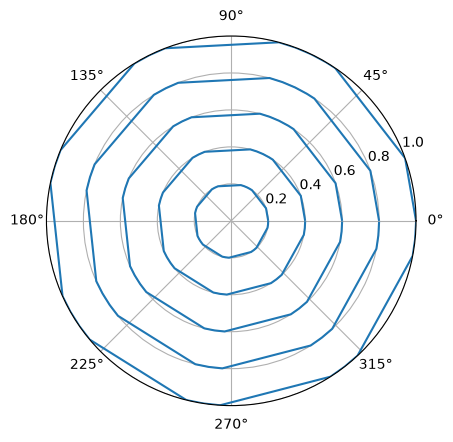

In [9]:
theta = np.linspace(0, 2*np.pi, 1000)[:-1]
r = np.linspace(0,1,100)

R, TH = np.meshgrid(theta,r)

X = R*np.cos(TH)
Y = R*np.sin(TH)

Bth = B_th(R, Bz)
U = -np.sin(TH)*Bth
V =  np.cos(TH)*Bth

ax = plt.subplot(polar=True)
ax.streamplot(theta, r, Bth, np.zeros(Bth.shape), arrowsize=0, density=.2 )
